In [5]:
import pandas as pd
import numpy as np

In [1]:
import os

os.makedirs("sql", exist_ok=True)

print("SQL folder created successfully!")

SQL folder created successfully!


In [2]:
import os
from sqlalchemy import create_engine, text
from sqlalchemy.engine import URL
from dotenv import load_dotenv
from getpass import getpass

# Load the .env file
load_dotenv()

# Read database credentials
user = os.getenv("DB_USER","root")
password = os.getenv("Charan@123")
host = os.getenv("DB_HOST","localhost")
database = os.getenv("DB_NAME","cart2insights")
port = int(os.getenv("DB_PORT","3306"))

# Check whether the password is availble
if not password:
    password = getpass(
    "Enter your MYSQL password: ")

#Create the MYSQL connection URL
connection_url = URL.create(
    drivername="mysql+pymysql",
    username='root',
    password='Charan@123',
    host='127.0.0.1',
    port=3306,
    database='cart2insights'
)

#create MYSQL connection

engine = create_engine(connection_url)

#Test the connection
try:
    with engine.connect() as connection:
        result = connection.execute(text("SELECT DATABASE()"))
        connected_database = result.scalar()
        print("Database connection successful!")
        print("Connected database:", connected_database)
except Exception as error:
    print("Database connection failed!")
    print("Error details:", error)
finally:
    engine.dispose()

Enter your MYSQL password:  ········


Database connection successful!
Connected database: cart2insights


In [13]:
%%writefile sql/analysis_queries.sql

-- CART2INSIGHTS SQL ANALYSIS
-- Reusable SQL queries

-- 1. BASIC SELECT
SELECT *
FROM products
LIMIT 10;

-- 2. COUNT AND AGGREGATION
SELECT COUNT(*) AS total_products
FROM products;

-- 3. GROUP BY AND ORDER BY
SELECT
    product_category_name,
    COUNT(*) AS total_products
FROM products
GROUP BY product_category_name
ORDER BY total_products DESC;

-- 4. WHERE CONDITION
SELECT *
FROM products
WHERE product_weight_g > 1000;

-- 5. HAVING CLAUSE
SELECT
    product_category_name,
    COUNT(*) AS total_products
FROM products
GROUP BY product_category_name
HAVING COUNT(*) > 100;

-- 6. CASE WHEN
SELECT
    product_id,
    product_weight_g,
    CASE
        WHEN product_weight_g > 1000 THEN 'Heavy'
        WHEN product_weight_g <= 1000 THEN 'Light'
        ELSE 'Unknown'
    END AS weight_category
FROM products;

-- 7. WINDOW FUNCTION
SELECT
    product_category_name,
    COUNT(*) AS total_products,
    RANK() OVER (
        ORDER BY COUNT(*) DESC
    ) AS category_rank
FROM products
GROUP BY product_category_name;

-- 8. Calculate monthly revenue based on Order Month for the only delivered orders

WITH order_totals AS (
    SELECT order_id, SUM(price + freight_value) AS order_value
    FROM order_items
    GROUP BY order_id
)
SELECT
    DATE_FORMAT( o.order_purchase_timestamp, '%Y-%m') AS order_month,
    SUM(ot.order_value) AS merchandise_and_freight
FROM orders o
JOIN order_totals ot
    ON o.order_id = ot.order_id
WHERE o.order_status = 'delivered'
GROUP BY DATE_FORMAT(
    o.order_purchase_timestamp, '%Y-%m'
)
ORDER BY order_month;


select * FROM order_items;

-- 9. To find the Top Selling based on Category_name

SELECT
        ct.product_category_name_english AS category_name,
	COUNT(DISTINCT oi.order_id) AS total_orders,
    COUNT(*) AS total_items_sold,
    ROUND(SUM(oi.price), 2) AS total_sales
FROM order_items oi
JOIN orders o
    ON oi.order_id = o.order_id
LEFT JOIN products p
    ON oi.product_id = p.product_id
LEFT JOIN category_translation ct
    ON p.product_category_name = ct.product_category_name
WHERE o.order_status = 'delivered'
GROUP BY category_name
ORDER BY total_sales DESC
LIMIT 10;

-- 10. Examples of Join

SELECT
    o.order_id,
    o.customer_id,
    o.order_status,
    o.order_purchase_timestamp
FROM orders o
JOIN customers c
    ON o.customer_id = c.customer_id;
    
-- 11. Which Customers Spend More Than the Average Customer
    
WITH customer_spending AS
(
    SELECT
        c.customer_unique_id,
        ROUND(SUM(oi.price), 2) AS total_spent
    FROM customers c
    JOIN orders o
        ON c.customer_id = o.customer_id
    JOIN order_items oi
        ON o.order_id = oi.order_id
    WHERE o.order_status = 'delivered'
    GROUP BY c.customer_unique_id)
SELECT
    customer_unique_id,
    total_spent
FROM customer_spending
WHERE total_spent >
(
    SELECT AVG(total_spent)
    FROM customer_spending
)
ORDER BY total_spent DESC;

-- 12. Find the Top Five Sellers by Revenue

WITH seller_revenue AS
(
    SELECT
        s.seller_id,
        s.seller_city,
        s.seller_state,
        COUNT(*) AS total_items_sold,
        ROUND(SUM(oi.price), 2) AS total_revenue
    FROM sellers s
    JOIN order_items oi
        ON s.seller_id = oi.seller_id
    JOIN orders o
        ON oi.order_id = o.order_id
    WHERE o.order_status = 'delivered'
    GROUP BY
        s.seller_id,
        s.seller_city,
        s.seller_state
),
seller_ranking AS
(
    SELECT
        seller_id,
        seller_city,
        seller_state,
        total_items_sold,
        total_revenue,
        DENSE_RANK() OVER (
            ORDER BY total_revenue DESC
        ) AS revenue_rank
    FROM seller_revenue
)
SELECT *
FROM seller_ranking
WHERE revenue_rank <= 5
ORDER BY revenue_rank, seller_id;


-- 13. Each Customer's Spending Rank

WITH customer_spending AS
(
    SELECT
        c.customer_unique_id,

        COUNT(DISTINCT o.order_id) AS total_orders,

        ROUND(SUM(oi.price), 2) AS total_spent

    FROM customers c

    JOIN orders o
        ON c.customer_id = o.customer_id

    JOIN order_items oi
        ON o.order_id = oi.order_id

    WHERE o.order_status = 'delivered'

    GROUP BY c.customer_unique_id
)

SELECT
    customer_unique_id,
    total_orders,
    total_spent,

    RANK() OVER (
        ORDER BY total_spent DESC
    ) AS spending_rank

FROM customer_spending

ORDER BY spending_rank, customer_unique_id;

    
-- 14. What is the running monthly revenue

WITH monthly_revenue AS
(
    SELECT
        DATE_FORMAT(
            o.order_purchase_timestamp,
            '%Y-%m'
        ) AS order_month,

        ROUND(SUM(oi.price), 2) AS monthly_sales

    FROM orders o

    JOIN order_items oi
        ON o.order_id = oi.order_id

    WHERE o.order_status = 'delivered'

    GROUP BY
        DATE_FORMAT(
            o.order_purchase_timestamp,
            '%Y-%m'
        )
)

SELECT
    order_month,
    monthly_sales,

    ROUND(
        SUM(monthly_sales) OVER (
            ORDER BY order_month
            ROWS BETWEEN UNBOUNDED PRECEDING
            AND CURRENT ROW
        ), 2
    ) AS running_monthly_revenue

FROM monthly_revenue

ORDER BY order_month;


Overwriting sql/analysis_queries.sql


In [14]:
# Read reusable SQL file
with open("sql/analysis_queries.sql", "r", encoding="utf-8") as file:
    sql_script = file.read()

# Separate the individual queries
queries = [
    q.strip()
    for q in sql_script.split(";")
    if q.strip()
]

# Execute and display each query
with engine.connect() as conn:
    for i, query in enumerate(queries, start=1):
        print(f"\nSQL Query {i}")

        df = pd.read_sql(text(query), conn)
        display(df)


SQL Query 1


,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
0,00066f42aeeb9f3007548bb9d3f33c38,perfumaria,53,596,6,300,20,16,16
1,00088930e925c41fd95ebfe695fd2655,automotivo,56,752,4,1225,55,10,26
2,0009406fd7479715e4bef61dd91f2462,cama_mesa_banho,50,266,2,300,45,15,35
3,000b8f95fcb9e0096488278317764d19,utilidades_domesticas,25,364,3,550,19,24,12
4,000d9be29b5207b54e86aa1b1ac54872,relogios_presentes,48,613,4,250,22,11,15
5,0011c512eb256aa0dbbb544d8dffcf6e,automotivo,58,177,1,100,16,15,16
6,00126f27c813603687e6ce486d909d01,cool_stuff,42,2461,1,700,25,5,15
7,001795ec6f1b187d37335e1c4704762e,consoles_games,53,274,1,600,30,20,20
8,001b237c0e9bb435f2e54071129237e9,cama_mesa_banho,42,253,1,6000,40,4,30
9,001b72dfd63e9833e8c02742adf472e3,moveis_decoracao,45,520,3,600,26,8,22



SQL Query 2


,total_products
0,32951



SQL Query 3


...

,seller_id,seller_city,seller_state,total_items_sold,total_revenue,revenue_rank
0,4869f7a5dfa277a7dca6462dcf3b52b2,guariba,SP,1148,226987.93,1
1,53243585a1d6dc2643021fd1853d8905,lauro de freitas,BA,400,217940.44,2
2,4a3ca9315b744ce9f8e9374361493884,ibitinga,SP,1949,196882.12,3
3,fa1c13f2614d7b5c4749cbc52fecda94,sumare,SP,579,190917.14,4
4,7c67e1448b00f6e969d365cea6b010ab,itaquaquecetuba,SP,1355,186570.05,5



SQL Query 14


,customer_unique_id,total_orders,total_spent,spending_rank
0,0a0a92112bd4c708ca5fde585afaa872,1,13440.00,1
1,da122df9eeddfedc1dc1f5349a1a690c,2,7388.00,2
2,763c8b1c9c68a0229c42c9fc6f662b93,1,7160.00,3
3,dc4802a71eae9be1dd28f5d788ceb526,1,6735.00,4
4,459bef486812aa25204be022145caa62,1,6729.00,5
...,...,...,...,...
93353,cf3839da0d9492ad151690b65f45d800,1,2.99,93354
93354,bd06ce0e06ad77a7f681f1a4960a3cc6,1,2.29,93355
93355,317cfc692e3f86c45c95697c61c853a6,1,2.20,93356
93356,b38211bd797f4fdd81a98b9d1754b606,1,0.85,93357



SQL Query 15


,order_month,monthly_sales,running_monthly_revenue
0,2016-09,134.97,134.97
1,2016-10,40325.11,40460.08
2,2016-12,10.90,40470.98
3,2017-01,111798.36,152269.34
4,2017-02,234223.40,386492.74
5,2017-03,359198.85,745691.59
6,2017-04,340669.68,1086361.27
7,2017-05,489338.25,1575699.52
8,2017-06,421923.37,1997622.89
9,2017-07,481604.52,2479227.41


In [7]:
query = """
SELECT
    product_category_name,
    COUNT(*) AS total_products
FROM products
WHERE product_category_name IS NOT NULL
GROUP BY product_category_name
ORDER BY total_products DESC
LIMIT 10
"""

df = pd.read_sql(text(query), engine)

display(df)

,product_category_name,total_products
0,cama_mesa_banho,3029
1,esporte_lazer,2867
2,moveis_decoracao,2657
3,beleza_saude,2444
4,utilidades_domesticas,2335
5,automotivo,1900
6,informatica_acessorios,1639
7,brinquedos,1411
8,relogios_presentes,1329
9,telefonia,1134


In [8]:
#Chart Creation

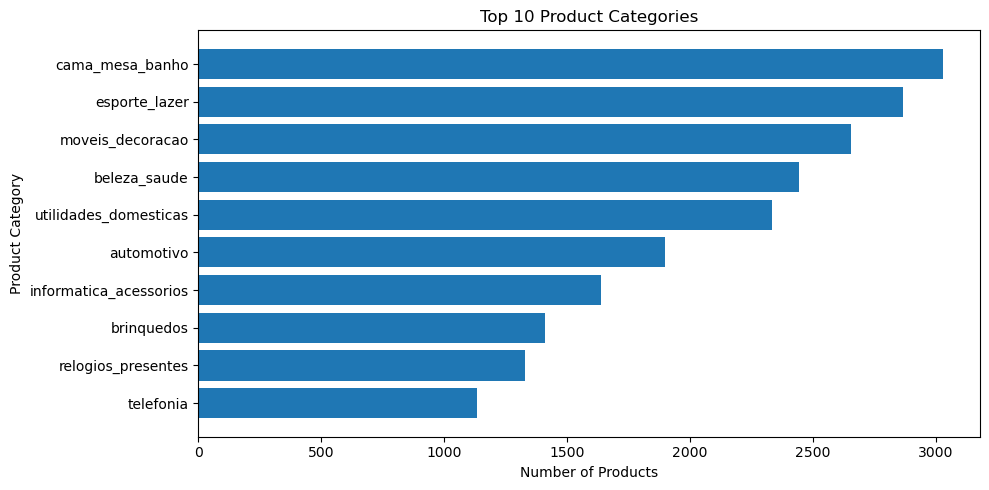

In [12]:
# Top 10 Product Category

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.barh(
    df["product_category_name"],
    df["total_products"]
)

plt.xlabel("Number of Products")
plt.ylabel("Product Category")
plt.title("Top 10 Product Categories")

plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()